# ¿Qué ve el modelo antes del fallo?

## Explicabilidad de TrajDev, el mejor detector individual del trabajo, en el parque C

*Mantenimiento Predictivo para Aerogeneradores Offshore con Restricciones Ambientales. Trabajo de
Fin de Máster. Tercero de los ocho notebooks y primero de los cuatro de explicabilidad, que forman
dos parejas (el mejor modelo individual en ambos parques y el ensemble campeón en ambos parques).*

## Resumen

Los detectores de anomalías sobre datos SCADA suelen evaluarse numéricamente y quedarse ahí. Este
notebook analiza el mejor modelo individual del trabajo (**TrajDev**, un detector de *desviación de
trayectoria* construido sobre un ensemble de forecasters GRU) y responde tres preguntas que un
número agregado no responde. **Qué** dispara cada alarma (sensores físicos con nombre), **cuándo**
empieza a verse el precursor (días u horas antes de la ventana de fallo), y **por qué** el modelo
alarma (¿se desvió el sensor, o el resto de la turbina dejó de predecirlo?).

La particularidad metodológica de TrajDev es que su score es **interpretable por construcción**. La
alarma es el máximo de un z-score por canal físico, así que la atribución sensor a sensor no
requiere ningún método post-hoc aproximado, basta mirar qué canal sostiene el máximo. Sobre esa
base exacta añadimos dos capas de validación independientes (gradientes integrados y oclusión),
siguiendo la pirámide *exacto --> gradiente --> perturbación* recomendada por la literatura de
explicabilidad para detección de anomalías, y un contrafactual simple ("sustituye el sensor
culpable por su pronóstico y mira si la alarma desaparece").

Resultado: en el parque C, TrajDev alcanza CARE-CV 0.7399 ± 0.0098 (5 semillas, supera al
autoencoder de referencia 5/5), y sus alarmas se pueden rastrear hasta sensores concretos con
antelaciones de hasta ~66 días en los mejores casos. Y el hallazgo más valioso del análisis está en
el precursor más claro del parque, donde la atribución por gradientes revela que la señal temprana
es **relacional**. No es que el sensor se desvíe, es que el resto de la turbina deja de predecirlo
semanas antes del fallo, que es la clase de aviso que justifica modelos multivariantes frente a
umbrales por sensor.

## 0. Preparación del entorno

Este notebook **no reentrena nada**, sino que carga los pesos de los modelos

In [1]:
# Preparacion del entorno comun a los 4 notebooks XAI
import os, sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
for p in (str(ROOT), str(ROOT / "scripts")):
    if p not in sys.path:
        sys.path.insert(0, p)
warnings.filterwarnings("ignore")

# ipykernel OutStream no tiene .buffer: evita que el guard utf-8 de los scripts del repo
# (if sys.stdout.encoding != "utf-8": sys.stdout = io.TextIOWrapper(sys.stdout.buffer, ...))
# intente envolverlo al importarlos.
for _s in (sys.stdout, sys.stderr):
    try:
        if getattr(_s, "encoding", None) != "utf-8":
            _s.encoding = "utf-8"
    except Exception:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.xai import (load_ae, load_ae_events, load_meta, load_scores, load_trajdev,
                     load_trajdev_events, trajdev_channel_z)
from src.xai.loaders import DEVICE, ae_scores, trajdev_forecast_errors, trajdev_score
from src.xai.cusum import cusum_series, first_alarm, h_sweep_best, official_cusum
from src.xai import plots as xp
from src.xai.attrib import (ae_integrated_gradients, ae_residual_sensor, occlusion_per_channel,
                            residual_train_stats, trajdev_counterfactual,
                            trajdev_integrated_gradients)
from src.care_official.adapter import OfficialCAREAdapter

xp.set_style()
np.random.seed(42); torch.manual_seed(42)
print(f"ROOT: {ROOT}")
print(f"dispositivo: {DEVICE} | torch {torch.__version__}")

ROOT: .
dispositivo: cuda | torch 2.10.0+cu128


In [2]:
# Los calculos pesados se cachean en results/xai_cache/nb1/
CACHE = ROOT / "results" / "xai_cache" / "nb1"
CACHE.mkdir(parents=True, exist_ok=True)

def cached(name, fn):
    """np.savez de dict de arrays; si existe, carga sin recomputar."""
    p = CACHE / f"{name}.npz"
    if p.exists():
        z = np.load(p, allow_pickle=True)
        return {k: z[k] for k in z.files}
    out = fn()
    np.savez_compressed(p, **out)
    return out

print(f"cache: {CACHE}")

cache: .\results\xai_cache\nb1


### 0.1 Verificación de reproducción

Antes de explicar nada, comprobamos que lo que hemos cargado es el modelo de campaña. El score
`dep_zmax_val`, ventana a ventana, debe coincidir con el volcado versionado que
produjo el CARE-CV oficial. Si esta celda falla, ninguna figura posterior es de fiar.

In [3]:
FARM = "C"
bundle = load_trajdev(FARM)
meta = load_meta(FARM)
events = load_trajdev_events(FARM)
_, ref_scores = load_scores(FARM, "own3_val")

# 3 eventos
for ev in events[:3]:
    err, _ = trajdev_forecast_errors(bundle, ev["data"])
    z = trajdev_channel_z(bundle, err)["z"]
    s = trajdev_score(bundle, z, "dep_zmax_val")
    d = float(np.max(np.abs(s - ref_scores[ev["event_id"]])))
    assert d < 1e-4, f"ev{ev['event_id']}: diff {d:.2e} — el modelo cargado NO reproduce el dump"
    print(f"ev{ev['event_id']:>3}: reproduccion exacta (max|diff| = {d:.1e}, {len(s):,} ventanas)")
print("GATE OK — el modelo cargado es el de campana.")

ev 55: reproduccion exacta (max|diff| = 0.0e+00, 3,167 ventanas)
ev 81: reproduccion exacta (max|diff| = 0.0e+00, 1,346 ventanas)


ev 47: reproduccion exacta (max|diff| = 0.0e+00, 1,551 ventanas)
GATE OK — el modelo cargado es el de campana.


## 1. Introducción

### 1.1 El problema

Los costes de operación y mantenimiento de los aerogeneradores *offshore* representan **entre el
25 % y el 50 % del coste total del ciclo de vida** de la instalación, frente al 10-20 % habitual
del coste nivelado de la energía en los parques terrestres, y una avería mayor de tren de potencia
implica semanas de indisponibilidad y una intervención con embarcación especializada. La apuesta
del mantenimiento predictivo es detectar el fallo **incipiente** en los datos SCADA de 10 minutos
que la turbina ya está registrando (temperatura de cojinetes y devanados, presiones hidráulicas,
potencia, viento) sin instrumentación adicional.

El planteamiento es necesariamente **no supervisado**, porque los fallos etiquetados son tan
escasos y tan heterogéneos que entrenar un clasificador es inviable. Se aprende el comportamiento
*normal* de la turbina y se alarma cuando la realidad se aparta de él de forma sostenida.

### 1.2 El banco de pruebas, CARE to Compare

Trabajamos con el *benchmark* público **CARE to Compare** (Gück, Roelofs y Faulstich, 2024). En su
parque C hay 22 turbinas marinas y 58 **eventos** de evaluación (27 anomalías reales con su ventana
de fallo etiquetada y 31 periodos normales), con 3 187 136 filas SCADA. Cada evento se puntúa con la
métrica oficial **CARE**, acrónimo de las cuatro dimensiones que evalúa:

- ***Coverage*** (cobertura): dentro de los *sub-datasets* anómalos, qué cantidad de la ventana
  previa al fallo se marca correctamente.
- ***Accuracy*** (exactitud): la tasa de acierto sobre los puntos normales de los *sub-datasets*
  normales, es decir, penaliza las falsas alarmas. **Pesa doble.**
- ***Reliability*** (fiabilidad): si lo detectado corresponde a fallos reales, a través del
  algoritmo de criticidad oficial.
- ***Earliness*** (anticipación): pondera cada alarma según su distancia temporal al fallo,
  premiando la detección temprana.

En todo el trabajo usamos además **CARE-CV**, donde el umbral de alarma se elige por validación
cruzada estratificada sobre eventos, de modo que el número reportado no lleva optimismo de umbral.

### 1.3 El modelo

**TrajDev** (*trajectory deviation*) es el mejor detector individual del trabajo. El mecanismo es de
**pronóstico y desviación** (*forecast-departure*). Un pequeño ensemble de redes recurrentes aprende
a pronosticar la trayectoria normal de las señales, y el *score* de una ventana es la desviación
entre lo observado y lo pronosticado, normalizada por canal.

La configuración final (v3) emplea un ensemble de **3 *forecasters* GRU** con contexto de 18 pasos
(3 horas) y horizonte de 9 (90 minutos), sobre las señales físicas derivadas del capítulo 5 de la
memoria ampliadas con los cien canales de valores escalados (las mismas variables que ve el
autoencoder). El *score*, `dep_zmax_val`, es el máximo sobre canales de la desviación normalizada,
con estadísticas de train (z-score *leakage-free*).

| Detector (parque C) | CARE-CV (5 semillas) | Semilla a semilla vs AE |
|---|--:|--:|
| **TrajDev `dep_zmax_val`** | **0.7399 ± 0.0098** | **gana 5/5** |
| Autoencoder BiLSTM (referencia) | 0.7206 ± 0.0165 | |

Es el único modelo individual del trabajo que supera al autoencoder de referencia con el rigor
completo, en las cinco semillas.

### 1.4 Qué significa "explicar" aquí

Seguimos tres principios tomados de la literatura de explicabilidad para detección de anomalías:

1. **Lo exacto antes que lo aproximado.** El *z* por canal de TrajDev *es* la atribución, no hay que
   estimarla. Los métodos aproximados (gradientes, oclusión) entran después, como validación.
2. **La atribución debe mirar la desviación, no solo el modelo.** Un gradiente explica qué cambia
   la salida del *modelo*, mientras que el residual por canal explica qué se *desvió de lo normal*
   (Idé et al., 2021). Presentamos siempre ambos.
3. **Continuidad con la literatura del propio conjunto de datos.** El grupo que publicó CARE
   publicó también ARCANA (Roelofs et al., 2021), atribución de causa raíz para autoencoders
   SCADA, de modo que nuestro análisis de ranking de sensores es directamente comparable con ese
   marco.

## 2. Datos y representación

### 2.1 Los 58 eventos de evaluación

Cada evento es un tramo continuo de una turbina concreta, con una parte de contexto y una **ventana
etiquetada** (anómala en los 27 eventos de fallo, típicamente las 2-4 semanas previas a la avería, o
normal en los 31 de control). El detector emite un score por cada ventana deslizante de 27 pasos
(4.5 horas) y un CUSUM secuencial convierte ese score en decisión de alarma.

In [4]:
rows = []
for e, m in meta.items():
    ts = m["window_timestamps"]
    rows.append({"evento": e, "etiqueta": m["event_label"], "turbina": m["asset_id"],
                 "ventanas": len(m["labels"]), "dias": (ts[-1] - ts[0]).total_seconds() / 86400.0,
                 "ventanas_anomalas": int(m["labels"].sum())})
df_ev = pd.DataFrame(rows).set_index("evento")
n_anom = int((df_ev["etiqueta"] == "anomaly").sum())
print(f"{len(df_ev)} eventos | {n_anom} anomalias, {len(df_ev)-n_anom} normales | "
      f"duracion media {df_ev['dias'].mean():.1f} dias | {df_ev['ventanas'].sum():,} ventanas de test")
df_ev.groupby("etiqueta").agg(
    n=("ventanas", "count"),
    ventanas_media=("ventanas", "mean"),
    dias_media=("dias", "mean"),
    ventanas_anomalas_media=("ventanas_anomalas", "mean"),
).round(1)

58 eventos | 27 anomalias, 31 normales | duracion media 18.8 dias | 157,020 ventanas de test


,n,ventanas_media,dias_media,ventanas_anomalas_media
etiqueta,,,,
anomaly,27,2858.8,19.8,2250.7
normal,31,2575.3,17.9,0.0


### 2.2 La representación, canales físicos con nombre

TrajDev trabaja sobre **304 canales físicos identificables**, que son las señales de valores medios
de los 100 sensores más informativos (`val__*`) más un panel de 204 señales físicas derivadas
(dispersión `std__`, rango `rng__`, asimetría `asym__` y coherencia de pares de sensores redundantes
`pav__`/`sdp__`, la misma física que explota el detector phys del ensemble campeón). Esta elección
es la que hace que la explicabilidad sea nativa, porque cuando el máximo del z lo sostiene
`val__sensor_15`, la frase "el sensor 15 se está desviando de su trayectoria esperada" es
directamente la explicación.

In [5]:
fam = pd.Series([c.split("__")[0] for c in bundle["ch_names"]]).value_counts()
print(f"K = {len(bundle['ch_names'])} canales | ctx {bundle['arch']['context']} pasos -> "
      f"horizonte {bundle['arch']['horizon']} pasos (90 min)")
print("familias de canales:", dict(fam))
print("ejemplos val__:", [c for c in bundle["ch_names"] if c.startswith("val__")][:6])

K = 304 canales | ctx 18 pasos -> horizonte 9 pasos (90 min)
familias de canales: {'val': np.int64(100), 'std': np.int64(62), 'rng': np.int64(62), 'asym': np.int64(62), 'sdp': np.int64(9), 'pav': np.int64(9)}
ejemplos val__: ['val__sensor_1', 'val__sensor_11', 'val__sensor_12', 'val__sensor_13', 'val__sensor_14', 'val__sensor_15']


## 3. El modelo, desviación de trayectoria

### 3.1 Fórmula

Para cada ventana de 27 pasos, el contexto (pasos 1-18) entra en cada uno de los 3 GRU del
ensemble, el pronóstico es la media de los tres, y el **tensor de error** es la diferencia con lo
realmente observado en los pasos 19-27. De ahí:

$$ z_c = \frac{\overline{|err_c|} - \mu_c^{train}}{\sigma_c^{train}} \qquad
   \text{score}(\text{ventana}) = \max_c z_c $$

donde $\mu_c, \sigma_c$ se calculan **solo con train** (sin fuga). El máximo, y no la media, es la
diferencia de diseño decisiva frente al autoencoder. Un fallo incipiente empieza en *un* subsistema,
y la media lo diluye entre decenas de canales sanos. La contrapartida es un score de cola pesada,
que el CUSUM secuencial (calibrado también solo con train) convierte en decisión estable.

In [6]:
n_par = sum(p.numel() for m in bundle["models"] for p in m.parameters())
print(f"ensemble: {len(bundle['models'])} x GRU(hidden={bundle['arch']['hidden']}) + cabeza directa "
      f"H*K | {n_par:,} parametros en total")
print(f"pesos: {bundle['ckpt']}")
print(f"z-stats de train guardadas: {sorted(bundle['z_stats'].keys())} (leakage-free, verificadas)")

ensemble: 3 x GRU(hidden=128) + cabeza directa H*K | 1,558,800 parametros en total
pesos: .\results\models\trajdev3_model_farm_c_s42.pt
z-stats de train guardadas: ['mu_c', 'mu_p', 'mu_s', 'sd_c', 'sd_p', 'sd_s'] (leakage-free, verificadas)


### 3.2 Punto de operación

Reconstruimos el barrido de umbral oficial sobre los scores versionados. El mejor punto del barrido
reproduce el CARE de la campaña, 0.7487 en esta semilla. Conviene saber qué es ese número, porque es
el CARE que se obtiene eligiendo el umbral **con las etiquetas a la vista**, y por eso no es el
número de decisión del trabajo, que sigue siendo el CARE-CV del apartado 1.3. Aquí el barrido nos
sirve solo para fijar el **punto de operación de los timelines** (h y CUSUM por evento) con el que
se dibujan todas las figuras del notebook.

In [7]:
adapter = OfficialCAREAdapter(raw_path="data/raw/CARE_To_Compare", farm=FARM, window_size=27)
train_dump, ev_dump = load_scores(FARM, "own3_val")

def _sweep():
    best = h_sweep_best(train_dump, ev_dump, meta, adapter)
    out = {f"S_{e}": v for e, v in best.pop("ev_S").items()}
    out["params"] = np.array([best["care"], best["h"], best["h_scale"], best["cov"], best["earl"],
                              best["rel"], best["acc"], best["mu"], best["k"], best["h_base"]])
    return out

sw = cached("sweep_oficial", _sweep)
care, H_OP, h_scale, cov, earl, rel, acc, MU, KREF, h_base = sw["params"]
EV_S = {e: sw[f"S_{e}"] for e in meta}
assert abs(care - 0.7487) < 2e-3, f"sweep no reproduce el CARE test-tuned de campana: {care:.4f}"
print(f"punto de operacion: h = {H_OP:.3f} (h_scale {h_scale:g})")
print(f"CARE test-tuned {care:.4f} | Cov {cov:.3f} Earl {earl:.3f} Rel {rel:.3f} Acc {acc:.3f}")

punto de operacion: h = 1708.403 (h_scale 1)
CARE test-tuned 0.7487 | Cov 0.674 Earl 0.466 Rel 0.791 Acc 0.906


El perfil del punto de operación ya nos muestra información sobre el modelo, **Accuracy 0.91** con
**Earliness 0.47**. TrajDev es un detector *conservador*, alarma poco a cambio de casi no
equivocarse en los periodos normales, que es exactamente lo que la métrica CARE premia. Es una
frontera entre Earliness y Accuracy que vimos durante la campaña, donde adelantar la alarma
comprando Earliness cuesta más Accuracy de la que la métrica devuelve.

## 4. Comportamiento global

### 4.1 Las 27 anomalías, una a una

Para cada evento anómalo, ¿hay alarma?, ¿con cuánta antelación respecto del final de la ventana de
fallo (*lead*)?, ¿con qué margen sobre el umbral (S/h)? Como referencia, la misma tabla para el
autoencoder en *su* punto de operación óptimo.

In [8]:
def _leads(det):
    train_d, ev_d = load_scores(FARM, det)
    best = h_sweep_best(train_d, ev_d, meta, adapter)
    out = {}
    for e, S in best["ev_S"].items():
        m = meta[e]
        lab = np.asarray(m["labels"], bool)
        idx = first_alarm(S, best["h"])
        lead = None
        if idx is not None and lab.any():
            lead = (m["window_timestamps"][np.flatnonzero(lab)[-1]] - m["window_timestamps"][idx]
                    ).total_seconds() / 3600.0
        out[e] = {"idx": idx, "lead": lead, "margen": float(S.max() / best["h"])}
    return best, out

best_td = ({"h": H_OP}, {e: {"idx": first_alarm(EV_S[e], H_OP), "margen": float(EV_S[e].max() / H_OP),
            "lead": None} for e in meta})
# leads TrajDev desde el sweep ya cacheado
for e, r in best_td[1].items():
    m, lab = meta[e], np.asarray(meta[e]["labels"], bool)
    if r["idx"] is not None and lab.any():
        r["lead"] = (m["window_timestamps"][np.flatnonzero(lab)[-1]] -
                     m["window_timestamps"][r["idx"]]).total_seconds() / 3600.0
_, leads_ae = _leads("ae")

anoms = [e for e in meta if meta[e]["event_label"] == "anomaly"]
tab = pd.DataFrame({
    "lead_TrajDev_h": {e: best_td[1][e]["lead"] for e in anoms},
    "margen_TrajDev": {e: best_td[1][e]["margen"] for e in anoms},
    "lead_AE_h": {e: leads_ae[e]["lead"] for e in anoms},
    "margen_AE": {e: leads_ae[e]["margen"] for e in anoms},
}).sort_values("lead_TrajDev_h", ascending=False)
det_td = tab["lead_TrajDev_h"].notna().sum()
det_ae = tab["lead_AE_h"].notna().sum()
print(f"anomalias con alarma: TrajDev {det_td}/27 | AE {det_ae}/27")
tab.round(1)

anomalias con alarma: TrajDev 24/27 | AE 26/27


,lead_TrajDev_h,margen_TrajDev,lead_AE_h,margen_AE
44,1582.0,11.2,1590.2,48.0
67,1095.0,1.4,1405.5,1.8
12,542.5,21.5,542.3,31.7
11,524.8,600.3,524.0,396.3
9,517.5,2.4,553.3,23.7
30,505.3,125.5,504.3,118.4
33,503.5,43.7,494.8,94.5
28,499.8,44.7,507.5,24.3
16,322.2,30.4,334.8,68.7
90,212.0,2.4,223.8,11.4


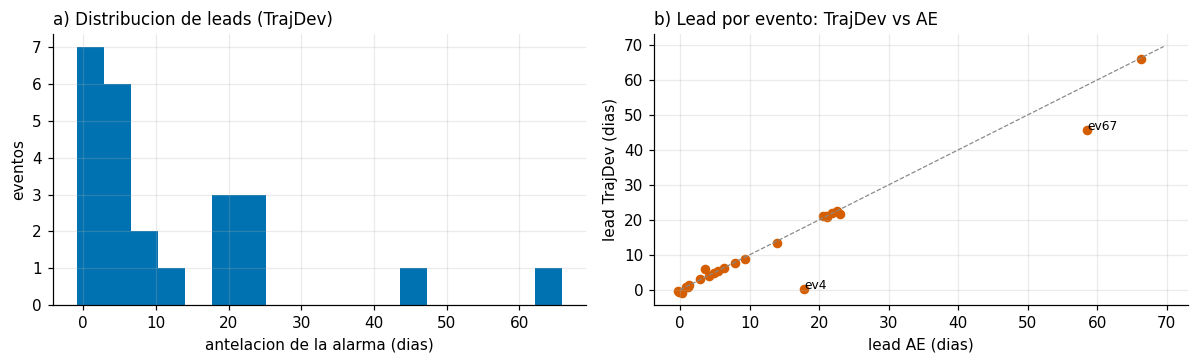

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ld = tab["lead_TrajDev_h"].dropna() / 24.0
axes[0].hist(ld, bins=18, color=xp.PALETTE[0])
axes[0].set_xlabel("antelacion de la alarma (dias)"); axes[0].set_ylabel("eventos")
axes[0].set_title("a) Distribucion de leads (TrajDev)", loc="left")
both = tab.dropna(subset=["lead_TrajDev_h", "lead_AE_h"])
axes[1].scatter(both["lead_AE_h"] / 24, both["lead_TrajDev_h"] / 24, s=28, color=xp.PALETTE[1])
lim = max(axes[1].get_xlim()[1], axes[1].get_ylim()[1])
axes[1].plot([0, lim], [0, lim], ls="--", lw=0.8, color="#888888")
for e, r in both.iterrows():
    if abs(r["lead_TrajDev_h"] - r["lead_AE_h"]) > 150:
        axes[1].annotate(f"ev{e}", (r["lead_AE_h"] / 24, r["lead_TrajDev_h"] / 24), fontsize=8)
axes[1].set_xlabel("lead AE (dias)"); axes[1].set_ylabel("lead TrajDev (dias)")
axes[1].set_title("b) Lead por evento: TrajDev vs AE", loc="left")
plt.tight_layout()

Tres lecturas.

(a) Los *leads* no son marginales, la mayoría de los fallos detectados se alarman con **días o
semanas** de antelación (hasta ~66 días en ev44).

(b) **TrajDev no gana al autoencoder por cobertura.** A sus respectivos puntos de operación detecta
24/27 frente a 26/27 del AE, y su ventaja en CARE viene de Accuracy (0.906 vs 0.862) y Reliability,
porque alarma menos y se equivoca menos, que es lo que la métrica (Accuracy×2) premia.

(c) En los eventos que ambos detectan, los leads caen casi sobre la diagonal (correlación de score
0.88), de modo que las divergencias son pocas pero informativas.

### 4.2 ¿Qué canales disparan las alarmas?

En el instante de disparo de cada alarma, ¿qué canal sostiene el máximo del z?

In [10]:
def _triggers():
    trig, zmaxs = [], []
    ev_by_id = {ev["event_id"]: ev for ev in events}
    for e in anoms:
        idx = best_td[1][e]["idx"]
        if idx is None:
            trig.append(-1); zmaxs.append(np.nan); continue
        ev = ev_by_id[e]
        sl = slice(max(0, idx - 3), min(len(ev["data"]), idx + 4))
        err, _ = trajdev_forecast_errors(bundle, ev["data"][sl])
        z = trajdev_channel_z(bundle, err)["z"]
        zm = z[:, bundle["masks"]["val"]] if "val" in bundle["masks"] else z
        val_idx = np.flatnonzero(bundle["masks"]["val"]) if "val" in bundle["masks"] else np.arange(z.shape[1])
        c_local = int(np.unravel_index(zm.argmax(), zm.shape)[1])
        trig.append(int(val_idx[c_local])); zmaxs.append(float(zm.max()))
    return {"trigger": np.array(trig), "zmax": np.array(zmaxs), "eventos": np.array(anoms)}

tr = cached("triggers_alarma", _triggers)
names = [bundle["ch_names"][c] if c >= 0 else "(sin alarma)" for c in tr["trigger"]]
cnt = pd.Series(names).value_counts()
print("canal disparador en el instante de alarma (27 anomalias):")
print(cnt.to_string())
resumen_trig = pd.DataFrame({"evento": tr["eventos"], "canal_disparador": names,
                             "z_max": np.round(tr["zmax"], 1)}).set_index("evento")

canal disparador en el instante de alarma (27 anomalias):
(sin alarma)       3
val__sensor_35     3
val__sensor_37     3
val__sensor_48     2
val__sensor_13     2
val__sensor_230    2
val__sensor_189    2
val__sensor_14     1
val__sensor_194    1
val__sensor_181    1
val__sensor_82     1
val__sensor_92     1
val__sensor_186    1
val__sensor_15     1
val__sensor_54     1
val__sensor_180    1
val__sensor_38     1


El disparo se concentra, **17 canales distintos sostienen las 24 alarmas**, con repetidores
claros (`sensor_35` y `sensor_37`, tres alarmas cada uno).

## 5. Casos de estudio

Cuatro eventos elegidos con criterio explícito:
- **ev11**, el precursor más nítido del parque, con margen S/h ≈ 600
- **ev66**, detección típica, margen ~100 y lead de 5-6 días
- **ev4**, la divergencia más informativa con el autoencoder, que alarma ~430 h antes que TrajDev
- **ev15**, fallo sin precursor que no ve ninguno de los dos, el límite del enfoque

Para cada caso, timeline de la alarma, mapa canal×tiempo del z, ranking de sensores, y en los dos
primeros la validación por gradientes, oclusión y contrafactual.

In [11]:
CASOS = [11, 66, 4, 15]
ev_by_id = {ev["event_id"]: ev for ev in events}

def z_evento(e):
    def _fn():
        ev = ev_by_id[e]
        err, dis = trajdev_forecast_errors(bundle, ev["data"])
        zf = trajdev_channel_z(bundle, err)
        return {"z": zf["z"], "z_slope": zf["z_slope"], "z_pers": zf["z_pers"]}
    return cached(f"z_ev{e}", _fn)

Z = {e: z_evento(e) for e in CASOS}
print({e: Z[e]["z"].shape for e in CASOS})

{11: (3995, 304), 66: (1781, 304), 4: (3863, 304), 15: (2711, 304)}


### 5.1 ev11

El caso más favorable del parque con margen máximo sobre el umbral de ~600× y alarma ~22 días antes
del final de la ventana de fallo. Si la explicabilidad nativa funciona, aquí tiene que verse un
canal (o un grupo pequeño y coherente) despegando de forma sostenida mucho antes de la etiqueta.

alarma: 2023-10-17 13:30:00 | antelacion 525 h (21.9 dias) | margen max S/h = 600


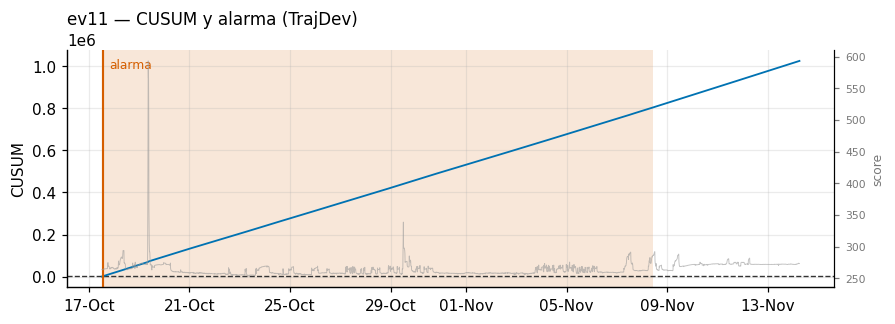

In [12]:
e = 11
ev = ev_by_id[e]
m = meta[e]
idx = best_td[1][e]["idx"]
s_e = trajdev_score(bundle, Z[e]["z"], "dep_zmax_val")
xp.plot_event_timeline(m["window_timestamps"], EV_S[e], H_OP, m["labels"], score=s_e,
                       alarm_idx=idx, title="ev11 — CUSUM y alarma (TrajDev)")
if idx is not None:
    lab = np.asarray(m["labels"], bool)
    lead = (m["window_timestamps"][np.flatnonzero(lab)[-1]] - m["window_timestamps"][idx])
    print(f"alarma: {m['window_timestamps'][idx]} | antelacion {lead.total_seconds()/3600:.0f} h "
          f"({lead.total_seconds()/86400:.1f} dias) | margen max S/h = {EV_S[e].max()/H_OP:.0f}")
else:
    print(f"SIN alarma al punto de operacion | margen max S/h = {EV_S[e].max()/H_OP:.2f}")

top-5:

 ['val__sensor_15', 'val__sensor_186', 'pav__sensor_153__sensor_186', 'val__sensor_115', 'sdp__reactive_power_121__reactive_power_122']


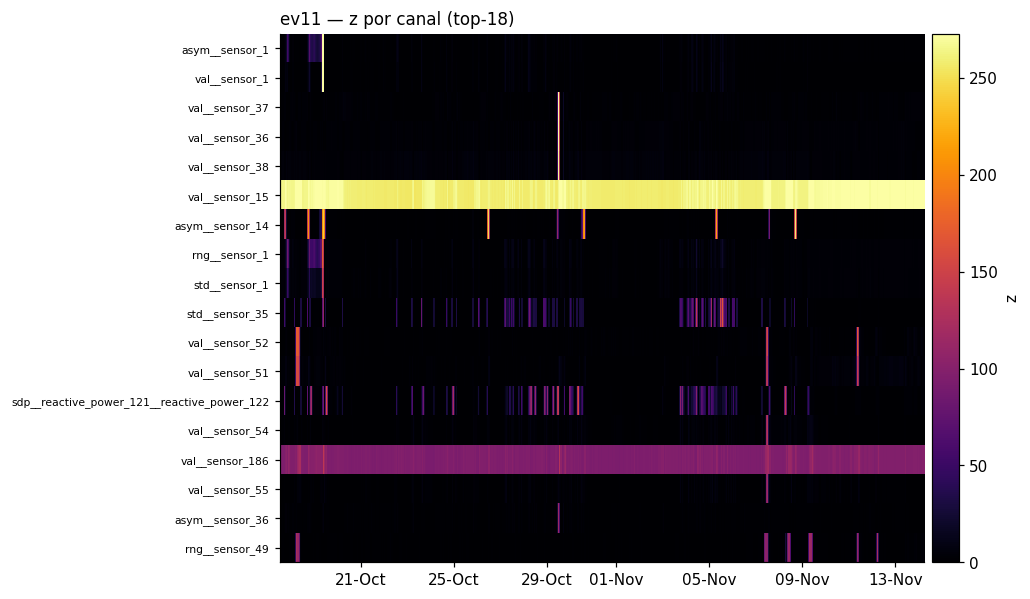

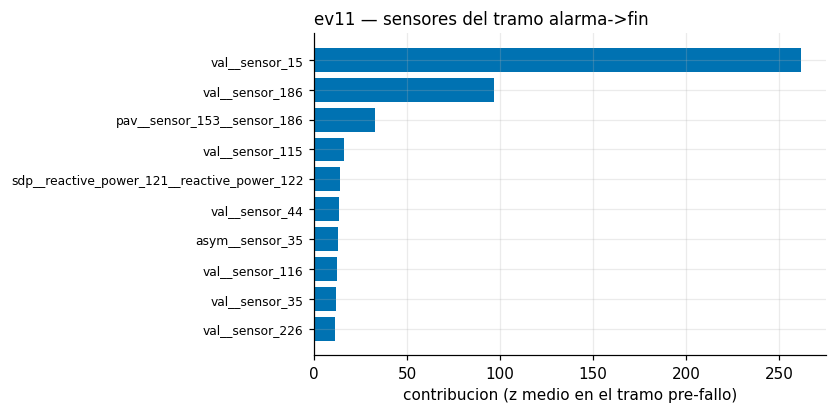

In [13]:
e = 11
m = meta[e]
ax, top_idx = xp.plot_channel_heatmap(m["window_timestamps"], np.clip(Z[e]["z"], 0, None),
                                      bundle["ch_names"], top=18,
                                      title=f"ev{e} — z por canal (top-18)")
# ranking en el tramo [alarma, fin de ventana etiquetada]
lab = np.asarray(m["labels"], bool)
i0 = best_td[1][e]["idx"] or (np.flatnonzero(lab)[0] if lab.any() else 0)
i1 = np.flatnonzero(lab)[-1] + 1 if lab.any() else len(lab)
zr = Z[e]["z"][i0:i1].mean(axis=0)
_ax, rank_idx = xp.plot_sensor_ranking(zr, bundle["ch_names"], top=10,
                                       title=f"ev{e} — sensores del tramo alarma->fin")
print("top-5:", [bundle["ch_names"][i] for i in rank_idx[::-1][:5]])

El heatmap muestra el patrón que define a un precursor real, un grupo reducido y *coherente* de
canales que se enciende de forma persistente tres semanas antes del final de la ventana, mientras
los otros ~300 canales permanecen en silencio. El grupo tiene estructura física, no estadística. Lo
encabezan `val__sensor_15` y `val__sensor_186`, acompañados por el canal de coherencia del par
redundante `pav__sensor_153__sensor_186` y por la coherencia de las potencias reactivas
(`sdp__reactive_power_121/122`), es decir, **el mismo subsistema visto por tres familias de señales
distintas** (el valor del sensor, su pareja redundante y la relación entre ambos).

**¿Se desvió el sensor, o dejó de ser predecible?** El z alto dice *que* el canal se aparta de su
pronóstico, no dice *por qué*. Los gradientes integrados sobre el forecaster separan las dos causas
posibles. Si la atribución se concentra en el propio canal dentro del contexto, el sensor se ha
desviado y arrastra su pronóstico; si se reparte por otros canales del contexto, es el resto de la
turbina el que ya no explica a este sensor (deriva **relacional**). Lo calculamos en tres ventanas,
pre-alarma, disparo y pico.

In [14]:
e = 11
ev = ev_by_id[e]
idx = best_td[1][e]["idx"]
lab = np.asarray(meta[e]["labels"], bool)
pico = int(EV_S[e].argmax())
wsel = {"pre-alarma": max(0, idx - 36), "disparo": idx, "pico": pico}
c_top = int(np.nanargmax(np.where(bundle["masks"]["val"], Z[e]["z"][idx], -np.inf)))
print(f"canal objetivo: {bundle['ch_names'][c_top]}")

def _ig11():
    normal = ev["data"][~lab][:400]
    base = np.median(normal, axis=0)
    att = trajdev_integrated_gradients(bundle, np.stack([ev["data"][i] for i in wsel.values()]),
                                       c_top, baseline_window=base, steps=50)
    return {"att": att, "base": base}

ig = cached(f"ig_ev{e}", _ig11)
ctx = bundle["arch"]["context"]
att = np.abs(ig["att"])
frac_propio = att[:, :ctx, c_top].sum(axis=1) / att[:, :ctx, :].sum(axis=(1, 2))
tabla_ig = pd.DataFrame({
    "ventana": list(wsel.keys()),
    "atrib_contexto_%": 100 * att[:, :ctx, :].sum(axis=(1, 2)) / att.sum(axis=(1, 2)),
    "propio_canal_en_ctx_%": 100 * frac_propio,
})
otros = att[:, :ctx, :].mean(axis=(0, 1))
otros[c_top] = 0
top_ctx = np.argsort(otros)[::-1][:5]
print("canales del CONTEXTO con mas atribucion (excl. el propio):",
      [bundle["ch_names"][i] for i in top_ctx])
tabla_ig.round(1)

canal objetivo: val__sensor_15
canales del CONTEXTO con mas atribucion (excl. el propio): ['val__sensor_35', 'rng__sensor_35', 'val__sensor_97', 'val__sensor_99', 'val__sensor_98']


,ventana,atrib_contexto_%,propio_canal_en_ctx_%
0,pre-alarma,90.699997,1.1
1,disparo,92.099998,0.9
2,pico,70.500000,4.2


**Anatomía de la alarma.** Todo lo anterior agrega sobre ventanas, y esta figura baja a UNA
instancia (la ventana exacta del disparo) para mostrar lo que el modelo tenía delante, el canal
disparador observado frente a su pronóstico (con la banda de desacuerdo del ensemble), y el mapa de
atribución IG de esa misma ventana (qué pasos y canales del contexto sostienen el error). Es la
explicación que acompañaría a la alarma en un sistema real.

instancia: ventana 6 (2023-10-17 13:30:00) | canal objetivo val__sensor_15 | z = 264.2


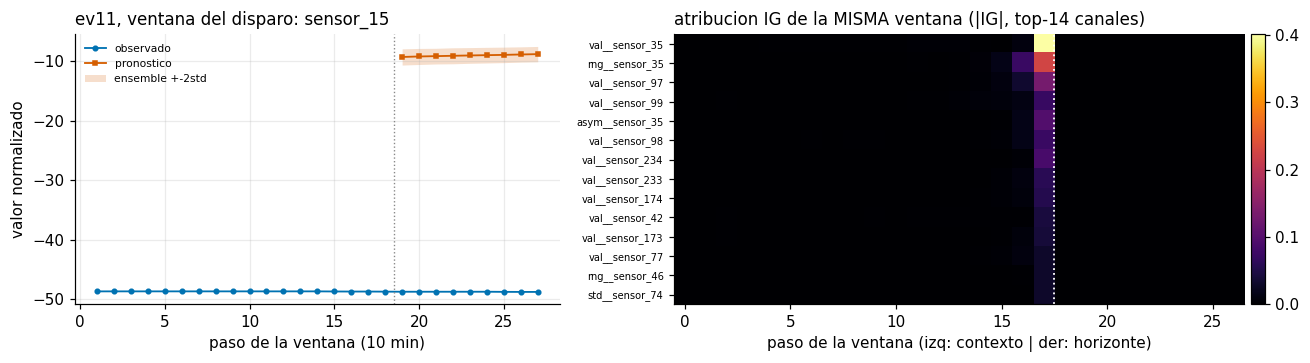

In [15]:
def anatomia_instancia(e, w_idx, titulo, c_obj=None, ax_pair=None):
    ev = ev_by_id[e]
    win = ev["data"][w_idx:w_idx + 1]
    ctx, h = bundle["arch"]["context"], bundle["arch"]["horizon"]
    if c_obj is None:
        err1, _ = trajdev_forecast_errors(bundle, win)
        z1 = trajdev_channel_z(bundle, err1)["z"][0]
        c_obj = int(np.nanargmax(np.where(bundle["masks"]["val"], z1, -np.inf)))
    x = torch.tensor(win[:, :ctx, :], dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        preds = np.stack([m(x).cpu().numpy()[0] for m in bundle["models"]])   # (M, H, K)
    obs = win[0, :, c_obj]
    f_mean, f_std = preds[:, :, c_obj].mean(axis=0), preds[:, :, c_obj].std(axis=0)
    if ax_pair is None:
        _, ax_pair = plt.subplots(1, 2, figsize=(12, 3.2), width_ratios=[1, 1.4])
    a0, a1 = ax_pair
    pasos = np.arange(1, ctx + h + 1)
    a0.plot(pasos, obs, marker="o", ms=3, lw=1.2, color=xp.PALETTE[0], label="observado")
    a0.plot(pasos[ctx:], f_mean, marker="s", ms=3, lw=1.2, color=xp.PALETTE[1], label="pronostico")
    a0.fill_between(pasos[ctx:], f_mean - 2 * f_std, f_mean + 2 * f_std, color=xp.PALETTE[1],
                    alpha=0.2, lw=0, label="ensemble +-2std")
    a0.axvline(ctx + 0.5, color="#888888", ls=":", lw=0.9)
    a0.set_xlabel("paso de la ventana (10 min)"); a0.set_ylabel("valor normalizado")
    a0.set_title(f"{titulo}: {bundle['ch_names'][c_obj].replace('val__','')}", loc="left")
    a0.legend(fontsize=7)
    return c_obj, a1

e = 11
idx = best_td[1][e]["idx"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.4), width_ratios=[1, 1.4])
c_obj, a1 = anatomia_instancia(e, idx, "ev11, ventana del disparo", c_obj=c_top, ax_pair=axes)
att_disparo = np.abs(ig["att"][1])                       # (27, 304), la ventana 'disparo' del IG cacheado
top_ig = np.argsort(att_disparo[:bundle["arch"]["context"]].sum(axis=0))[::-1][:14]
im = a1.imshow(att_disparo[:, top_ig].T, aspect="auto", cmap="inferno", interpolation="nearest")
a1.axvline(bundle["arch"]["context"] - 0.5, color="white", ls=":", lw=1.2)
a1.set_yticks(range(len(top_ig))); a1.set_yticklabels([bundle["ch_names"][i] for i in top_ig], fontsize=6.5)
a1.set_xlabel("paso de la ventana (izq: contexto | der: horizonte)")
a1.set_title("atribucion IG de la MISMA ventana (|IG|, top-14 canales)", loc="left")
a1.grid(False)
plt.colorbar(im, ax=a1, pad=0.01)
plt.tight_layout()
print(f"instancia: ventana {idx} ({meta[e]['window_timestamps'][idx]}) | canal objetivo "
      f"{bundle['ch_names'][c_obj]} | z = {Z[e]['z'][idx, c_obj]:.1f}")

**Contrafactual.** Sustituimos el tramo objetivo del canal disparador por su propio pronóstico
("¿y si este sensor se hubiera comportado como se esperaba?") y recomputamos score y CUSUM. Si la
alarma se desploma, el canal identificado **explica** la alarma; si apenas cambia, la atribución
sería decorativa.

pico CUSUM: 1025613.3 -> 365012.2  (reduccion 64%) | score medio en ventana anomala: 262.45 -> 98.91


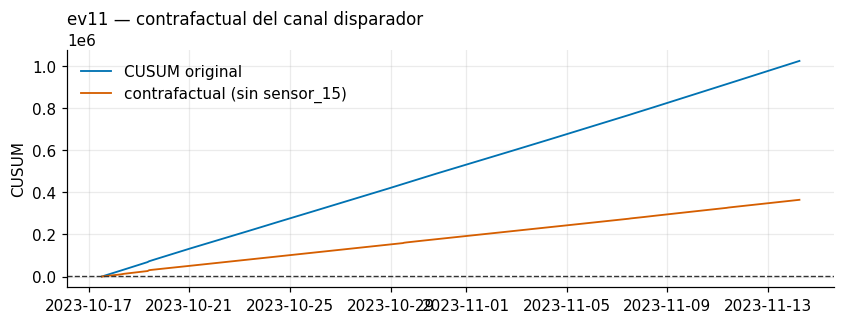

In [16]:
def _cf11():
    cf = trajdev_counterfactual(bundle, ev["data"], c_top)
    err_cf, _ = trajdev_forecast_errors(bundle, cf)
    z_cf = trajdev_channel_z(bundle, err_cf)["z"]
    return {"s_cf": trajdev_score(bundle, z_cf, "dep_zmax_val")}

cf = cached(f"cf_ev{e}", _cf11)
s_orig = trajdev_score(bundle, Z[e]["z"], "dep_zmax_val")
S_cf = cusum_series(cf["s_cf"], MU, KREF)
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(meta[e]["window_timestamps"], EV_S[e], lw=1.2, label="CUSUM original")
ax.plot(meta[e]["window_timestamps"], S_cf, lw=1.2, label=f"contrafactual (sin {bundle['ch_names'][c_top].replace('val__','')})")
ax.axhline(H_OP, color="#333333", ls="--", lw=0.9)
ax.legend(); ax.set_title("ev11 — contrafactual del canal disparador", loc="left")
ax.set_ylabel("CUSUM")
red = 100 * (1 - S_cf.max() / EV_S[e].max())
print(f"pico CUSUM: {EV_S[e].max():.1f} -> {S_cf.max():.1f}  (reduccion {red:.0f}%)"
      f" | score medio en ventana anomala: {s_orig[lab].mean():.2f} -> {cf['s_cf'][lab].mean():.2f}")

Los dos experimentos convergen en un diagnóstico más fino que "el sensor 15 está raro":

- **La deriva es relacional, no local.** El IG asigna ~90% de la atribución al *contexto* y solo
  ~1% al propio canal dentro de él. El pronóstico de `sensor_15` no falla porque `sensor_15` se
  desvíe, sino porque **el resto de la turbina (liderado por `sensor_35`, `sensor_97-99`) ya no lo
  explica**. La relación se rompió semanas antes de la etiqueta, que es el tipo de precursor que un
  umbral univariante sobre el propio sensor no puede ver.
- **El contrafactual confirma un precursor de grupo.** Neutralizar el canal disparador tumba el
  pico del CUSUM un 64% (y el score medio del tramo anómalo de 262 a 99), pero la alarma **no
  desaparece**, la sostienen `sensor_186` y los canales de coherencia del par 153-186. La causa no
  es un sensor sino un subsistema, y la atribución lo resuelve a esa granularidad.

### 5.2 ev66, la detección típica

Margen ~100× y 5.5 días de antelación. Representa el comportamiento mediano del detector, con el
mismo análisis en versión compacta y un contraste instructivo con ev11, porque aquí el contrafactual
elimina el **90%** del pico del CUSUM, es decir, la alarma es esencialmente **un solo canal**
(`sensor_181`). Los dos regímenes de precursor, grupo coherente (ev11) y canal único (ev66), son los
dos extremos que el operador encontrará en la práctica.

alarma: 2023-01-18 01:30:00 | antelacion 131 h (5.5 dias) | margen max S/h = 101


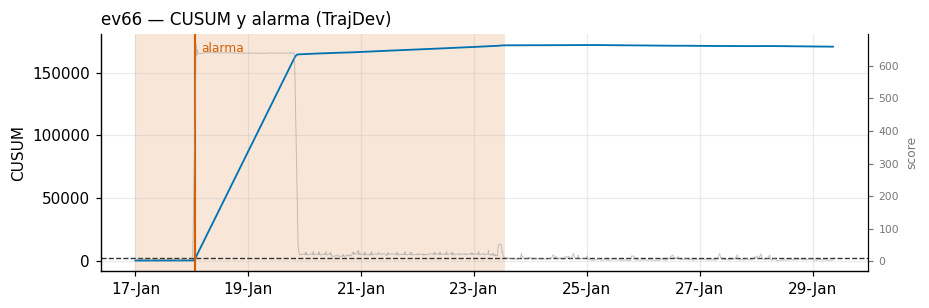

In [17]:
e = 66
ev = ev_by_id[e]
m = meta[e]
idx = best_td[1][e]["idx"]
s_e = trajdev_score(bundle, Z[e]["z"], "dep_zmax_val")
xp.plot_event_timeline(m["window_timestamps"], EV_S[e], H_OP, m["labels"], score=s_e,
                       alarm_idx=idx, title="ev66 — CUSUM y alarma (TrajDev)")
if idx is not None:
    lab = np.asarray(m["labels"], bool)
    lead = (m["window_timestamps"][np.flatnonzero(lab)[-1]] - m["window_timestamps"][idx])
    print(f"alarma: {m['window_timestamps'][idx]} | antelacion {lead.total_seconds()/3600:.0f} h "
          f"({lead.total_seconds()/86400:.1f} dias) | margen max S/h = {EV_S[e].max()/H_OP:.0f}")
else:
    print(f"SIN alarma al punto de operacion | margen max S/h = {EV_S[e].max()/H_OP:.2f}")

top-5:

 ['val__sensor_181', 'val__sensor_35', 'val__sensor_226', 'val__sensor_191', 'val__sensor_192']


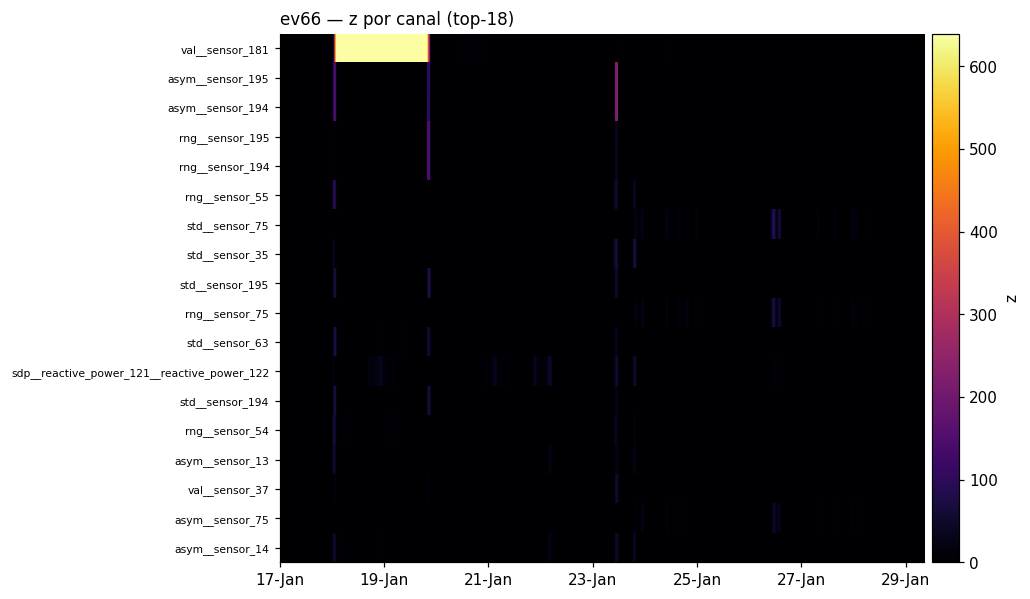

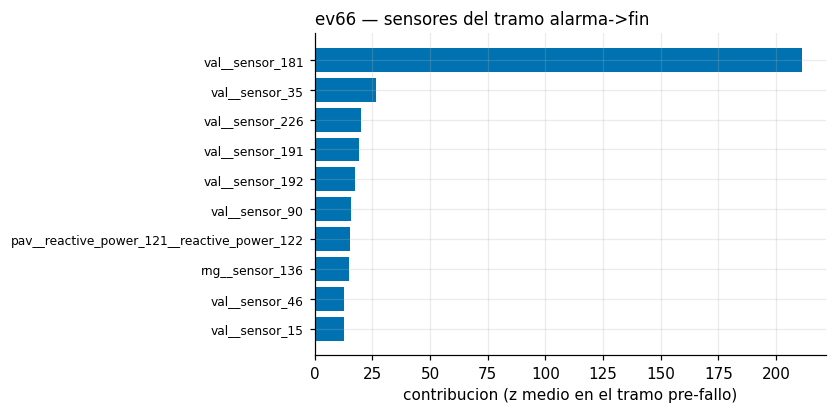

In [18]:
e = 66
m = meta[e]
ax, top_idx = xp.plot_channel_heatmap(m["window_timestamps"], np.clip(Z[e]["z"], 0, None),
                                      bundle["ch_names"], top=18,
                                      title=f"ev{e} — z por canal (top-18)")
# ranking en el tramo [alarma, fin de ventana etiquetada]
lab = np.asarray(m["labels"], bool)
i0 = best_td[1][e]["idx"] or (np.flatnonzero(lab)[0] if lab.any() else 0)
i1 = np.flatnonzero(lab)[-1] + 1 if lab.any() else len(lab)
zr = Z[e]["z"][i0:i1].mean(axis=0)
_ax, rank_idx = xp.plot_sensor_ranking(zr, bundle["ch_names"], top=10,
                                       title=f"ev{e} — sensores del tramo alarma->fin")
print("top-5:", [bundle["ch_names"][i] for i in rank_idx[::-1][:5]])

In [19]:
e = 66
ev = ev_by_id[e]
idx = best_td[1][e]["idx"]
lab = np.asarray(meta[e]["labels"], bool)
c_top = int(np.nanargmax(np.where(bundle["masks"]["val"], Z[e]["z"][idx], -np.inf)))

def _cf66():
    cf_w = trajdev_counterfactual(bundle, ev["data"], c_top)
    err_cf, _ = trajdev_forecast_errors(bundle, cf_w)
    return {"s_cf": trajdev_score(bundle, trajdev_channel_z(bundle, err_cf)["z"], "dep_zmax_val")}

cf66 = cached(f"cf_ev{e}", _cf66)
S_cf = cusum_series(cf66["s_cf"], MU, KREF)
print(f"canal disparador: {bundle['ch_names'][c_top]}")
print(f"pico CUSUM {EV_S[e].max():.1f} -> {S_cf.max():.1f} "
      f"({100*(1-S_cf.max()/EV_S[e].max()):.0f}% de reduccion al sustituirlo por su pronostico)")

canal disparador: val__sensor_181
pico CUSUM 172108.6 -> 17434.1 (90% de reduccion al sustituirlo por su pronostico)


**La instancia, antes y durante.** El mismo canal y la misma figura de pronóstico frente a
observado en dos ventanas, dos días antes de la alarma (donde el pronóstico sigue la señal con
precisión) y en el disparo (donde la señal se sale de la banda del ensemble). La diferencia entre
ambas *es* el score.

canal: val__sensor_181 | z en disparo = 514.6 | z 2 dias antes = -0.1


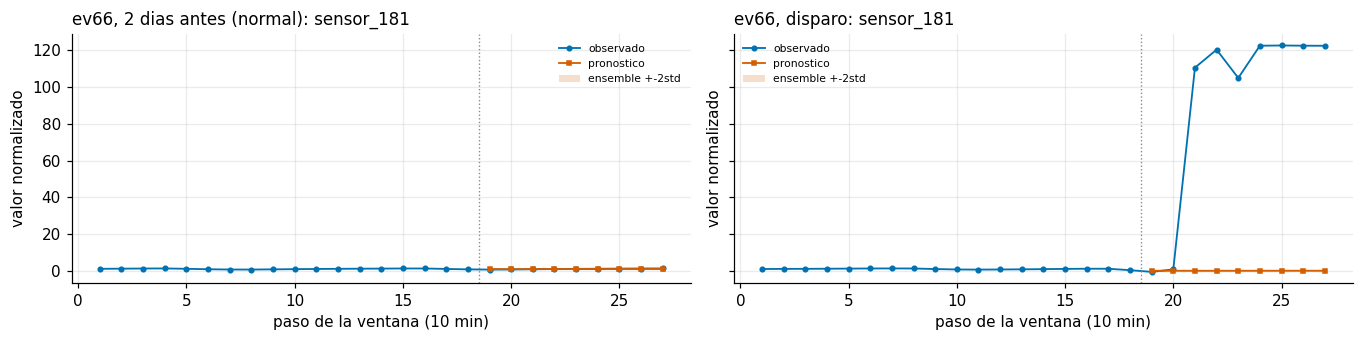

In [20]:
e = 66
idx = best_td[1][e]["idx"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.2), sharey=True)
c66, _ = anatomia_instancia(e, idx, "ev66, disparo", ax_pair=(axes[1], axes[1]))
_, _ = anatomia_instancia(e, max(0, idx - 288), "ev66, 2 dias antes (normal)", c_obj=c66,
                          ax_pair=(axes[0], axes[0]))
plt.tight_layout()
print(f"canal: {bundle['ch_names'][c66]} | z en disparo = {Z[e]['z'][idx, c66]:.1f} "
      f"| z 2 dias antes = {Z[e]['z'][max(0, idx - 288), c66]:.1f}")

### 5.3 ev4, cuando el autoencoder ve antes

La mayor divergencia de la tabla del apartado 4.1 es que el AE alarma ~430 horas antes del final de
la ventana y TrajDev apenas ~5. Es el caso adecuado para comparar las **atribuciones de dos modelos
distintos sobre el mismo fallo**. ¿Están mirando cosas diferentes, o lo mismo con sensibilidades
distintas?

alarma: 2023-08-19 04:50:00 | antelacion 5 h (0.2 dias) | margen max S/h = 8


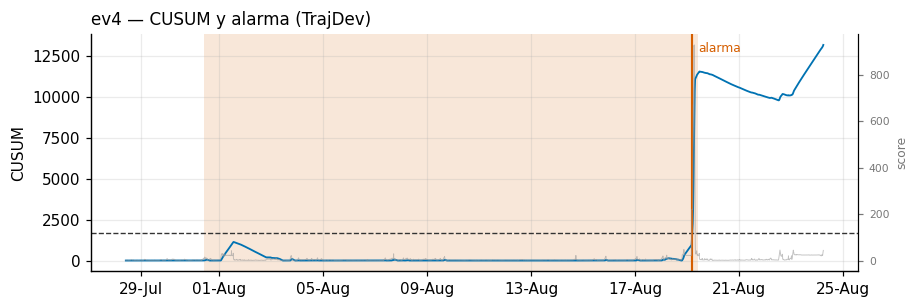

In [21]:
e = 4
ev = ev_by_id[e]
m = meta[e]
idx = best_td[1][e]["idx"]
s_e = trajdev_score(bundle, Z[e]["z"], "dep_zmax_val")
xp.plot_event_timeline(m["window_timestamps"], EV_S[e], H_OP, m["labels"], score=s_e,
                       alarm_idx=idx, title="ev4 — CUSUM y alarma (TrajDev)")
if idx is not None:
    lab = np.asarray(m["labels"], bool)
    lead = (m["window_timestamps"][np.flatnonzero(lab)[-1]] - m["window_timestamps"][idx])
    print(f"alarma: {m['window_timestamps'][idx]} | antelacion {lead.total_seconds()/3600:.0f} h "
          f"({lead.total_seconds()/86400:.1f} dias) | margen max S/h = {EV_S[e].max()/H_OP:.0f}")
else:
    print(f"SIN alarma al punto de operacion | margen max S/h = {EV_S[e].max()/H_OP:.2f}")

margen AE S/h = 5.1 | margen TrajDev S/h = 7.71


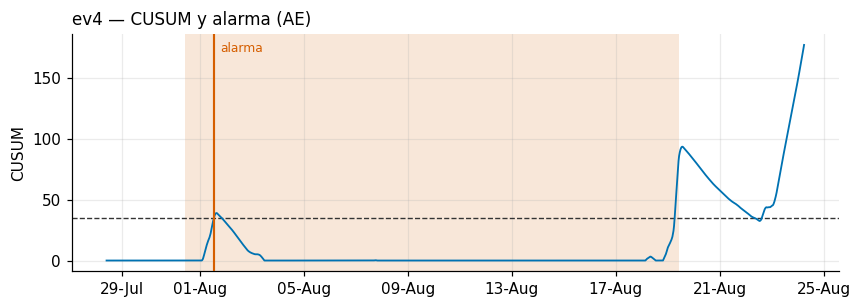

In [22]:
e = 4
m = meta[e]
# timeline del AE en el mismo evento
_, ev_ae = load_scores(FARM, "ae")
mu_a, k_a, hb_a = official_cusum(load_scores(FARM, "ae")[0])
S_ae = cusum_series(ev_ae[e], mu_a, k_a)
h_ae = hb_a * 0.002   # h_scale oficial del AE deployed
xp.plot_event_timeline(m["window_timestamps"], S_ae, h_ae, m["labels"],
                       alarm_idx=first_alarm(S_ae, h_ae), title="ev4 — CUSUM y alarma (AE)")
print(f"margen AE S/h = {S_ae.max()/h_ae:.1f} | margen TrajDev S/h = {EV_S[e].max()/H_OP:.2f}")

TrajDev top-8: ['std__sensor_14', 'sensor_14', 'asym__sensor_14', 'rng__sensor_55', 'std__sensor_35', 'sdp__reactive_power_121__reactive_power_122', 'rng__sensor_35', 'sensor_35']
AE      top-8: ['sensor_225_avg', 'sensor_189_avg', 'sensor_218_avg', 'sensor_42_avg', 'sensor_150_avg', 'sensor_65_avg', 'sensor_91_avg', 'sensor_88_avg']
solape top-8: []


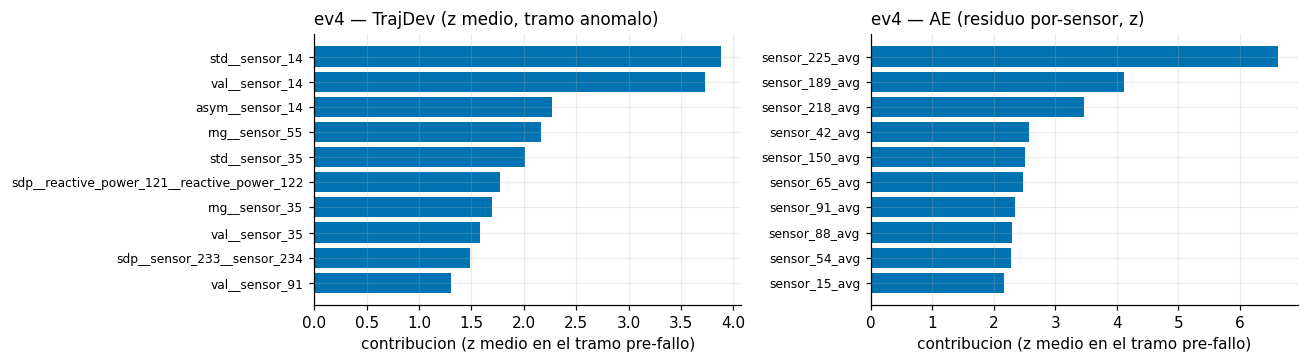

In [23]:
# atribucion comparada en el tramo anomalo: z TrajDev vs residuo por-sensor del AE (z de train-normal)
e = 4
lab = np.asarray(meta[e]["labels"], bool)

def _ae_attr_ev4():
    ae = load_ae(FARM)
    aev = {x["event_id"]: x for x in load_ae_events(FARM)}[e]
    res = ae_residual_sensor(ae, aev["raw"])                      # (N, F) espacio sensor
    normal = res[~lab] if (~lab).any() else res[:200]
    mu_r, sd_r = residual_train_stats(normal)
    return {"zres": (res - mu_r) / sd_r, "feats": np.array(ae["feats"])}

aa = cached(f"ae_attr_ev{e}", _ae_attr_ev4)
z_td = Z[e]["z"][lab].mean(axis=0)
z_ae = aa["zres"][lab].mean(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
xp.plot_sensor_ranking(z_td, bundle["ch_names"], top=10, ax=axes[0],
                       title="ev4 — TrajDev (z medio, tramo anomalo)")
xp.plot_sensor_ranking(z_ae, list(aa["feats"]), top=10, ax=axes[1],
                       title="ev4 — AE (residuo por-sensor, z)")
plt.tight_layout()
td_top = [bundle["ch_names"][i].replace("val__", "") for i in np.argsort(z_td)[::-1][:8]]
ae_top = [str(f) for f in aa["feats"][np.argsort(z_ae)[::-1][:8]]]
print("TrajDev top-8:", td_top)
print("AE      top-8:", ae_top)
print("solape top-8:", sorted(set(td_top) & set(ae_top)))

El solape entre los top-8 de ambos modelos es **vacío**, no es que uno sea más sensible que el
otro. Están viendo físicas distintas del mismo fallo. El autoencoder dispara pronto por un patrón
difuso repartido entre sensores de proceso (225, 189, 218, 42...) cuya *combinación* es atípica, un
estado poco frecuente que la reconstrucción detecta aunque cada señal individual evolucione con
suavidad. TrajDev, que pregunta si la trayectoria de cada canal sigue su pronóstico, no ve gran cosa
precisamente porque esas trayectorias siguen siendo predecibles, y su débil respuesta tardía llega
por la familia del sensor_14/35 y el par de potencias reactivas. La divergencia queda explicada **por
diseño** (reconstrucción de estado frente a desviación de trayectoria), y es el argumento de por qué
el ensemble del trabajo combina familias, porque hay fallos de estado y fallos de trayectoria, y
ningún score único cubre ambos.

### 5.4 ev15, el fallo sin precursor en los valores

Margen 0.2× para TrajDev y 0.1× para el autoencoder, ninguno de los dos ve *nada*. Este evento
ilustra el techo de los detectores **de valores**, la familia de fallos (típicamente eléctricos o
abruptos) cuyos sensores no derivan de forma visible antes de la etiqueta, y que limita la cobertura
alcanzable en este parque. El heatmap plano de abajo indica que aquí no hay señal en los valores, y no un fallo del método de atribución.

SIN alarma al punto de operacion | margen max S/h = 0.21


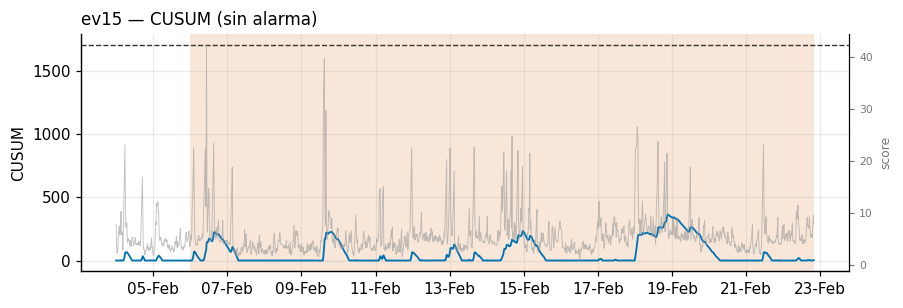

In [24]:
e = 15
ev = ev_by_id[e]
m = meta[e]
idx = best_td[1][e]["idx"]
s_e = trajdev_score(bundle, Z[e]["z"], "dep_zmax_val")
xp.plot_event_timeline(m["window_timestamps"], EV_S[e], H_OP, m["labels"], score=s_e,
                       alarm_idx=idx, title="ev15 — CUSUM (sin alarma)")
if idx is not None:
    lab = np.asarray(m["labels"], bool)
    lead = (m["window_timestamps"][np.flatnonzero(lab)[-1]] - m["window_timestamps"][idx])
    print(f"alarma: {m['window_timestamps'][idx]} | antelacion {lead.total_seconds()/3600:.0f} h "
          f"({lead.total_seconds()/86400:.1f} dias) | margen max S/h = {EV_S[e].max()/H_OP:.0f}")
else:
    print(f"SIN alarma al punto de operacion | margen max S/h = {EV_S[e].max()/H_OP:.2f}")

top-5: ['std__sensor_44', 'asym__sensor_44', 'val__sensor_81', 'rng__sensor_44', 'rng__sensor_54']


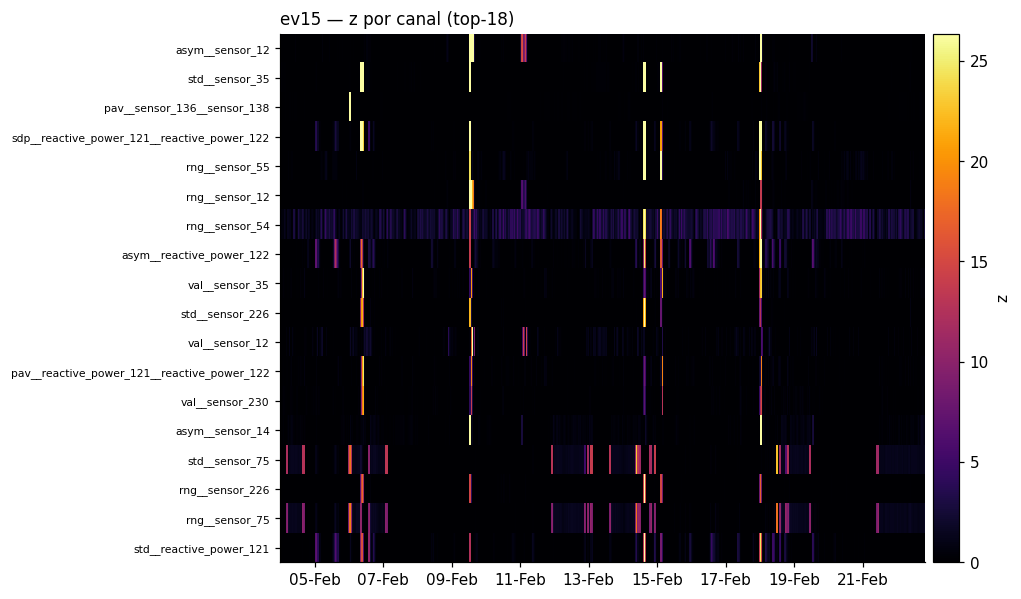

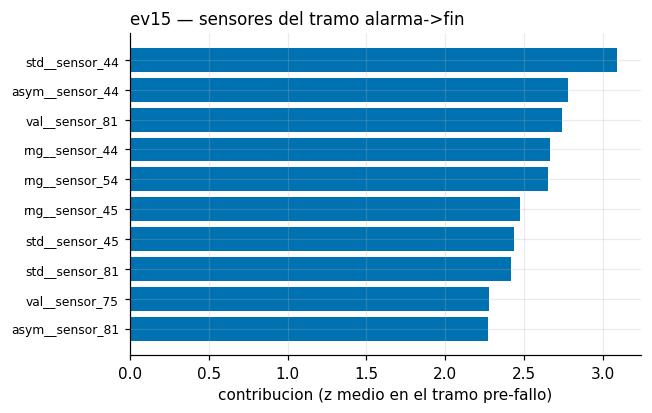

In [25]:
e = 15
m = meta[e]
ax, top_idx = xp.plot_channel_heatmap(m["window_timestamps"], np.clip(Z[e]["z"], 0, None),
                                      bundle["ch_names"], top=18,
                                      title=f"ev{e} — z por canal (top-18)")
# ranking en el tramo [alarma, fin de ventana etiquetada]
lab = np.asarray(m["labels"], bool)
i0 = best_td[1][e]["idx"] or (np.flatnonzero(lab)[0] if lab.any() else 0)
i1 = np.flatnonzero(lab)[-1] + 1 if lab.any() else len(lab)
zr = Z[e]["z"][i0:i1].mean(axis=0)
_ax, rank_idx = xp.plot_sensor_ranking(zr, bundle["ch_names"], top=10,
                                       title=f"ev{e} — sensores del tramo alarma->fin")
print("top-5:", [bundle["ch_names"][i] for i in rank_idx[::-1][:5]])

## 6. Validación cruzada de las atribuciones

El z por canal es exacto respecto del *score*, pero ¿identifica de verdad los canales que sostienen
la anomalía? Lo contrastamos con **oclusión**, un método de perturbación independiente, sustituyendo
canales candidatos por su nivel normal y midiendo cuánto cae el score.

Con dos salvedades metodológicas que los propios resultados obligan a respetar:

1. **La perturbación debe respetar la naturaleza del score.** Para un detector de *pronóstico*,
   sustituir un canal por un valor constante (la oclusión clásica de los modelos de reconstrucción)
   rompe la dinámica de la señal y produce resultados **erráticos**. Lo comprobamos como control, y
   en un caso el score ni se inmuta (la señal aplanada es tan imprevisible como la anómala) y en
   otro se desploma por la razón equivocada. La perturbación coherente es el **contrafactual**,
   sustituir el tramo objetivo por el propio pronóstico del modelo, es decir, suponer que ese canal
   se comportó exactamente como se esperaba.
2. **Bajo agregación max, el efecto por canal es no aditivo.** En un precursor de **grupo** (ev11),
   neutralizar el canal líder deja el máximo en manos del siguiente del grupo, los deltas
   individuales son planos y el ranking pierde sentido. La prueba correcta para grupos es el
   **contrafactual acumulado** top-k, que neutraliza conjuntos crecientes y mide la caída. En un
   precursor de **canal único** (ev66), el efecto individual sí debe ser dominante.

In [26]:
def _score_fn(w):
    err, _ = trajdev_forecast_errors(bundle, w)
    return trajdev_score(bundle, trajdev_channel_z(bundle, err)["z"], "dep_zmax_val")

def _cf_val(e, top=8):
    # Validacion por CONTRAFACTUAL
    # delta por-canal (sustituir cada candidato por su pronostico)
    # + contrafactual ACUMULADO top-k.
    ev = ev_by_id[e]
    lab = np.asarray(meta[e]["labels"], bool)
    idx = best_td[1][e]["idx"] or int(EV_S[e].argmax())
    wins = ev["data"][idx:idx + 24]
    cand = list(np.argsort(Z[e]["z"][idx:idx + 24].mean(axis=0))[::-1][:top])
    base = float(_score_fn(wins).mean())
    delta = np.array([base - float(_score_fn(trajdev_counterfactual(bundle, wins, c)).mean())
                      for c in cand])
    cum = np.array([float(_score_fn(trajdev_counterfactual(bundle, wins, cand[:k])).mean())
                    for k in range(1, 7)])
    normal = ev["data"][~lab][:400]
    fill = np.median(normal, axis=(0, 1))
    occ_const = occlusion_per_channel(_score_fn, wins, fill, channels=cand[:4]).mean(axis=0)
    return {"cand": np.array(cand), "delta": delta, "cum": cum, "base": np.array([base]),
            "z_rank": Z[e]["z"][idx:idx + 24].mean(axis=0)[cand], "occ_const": occ_const}

from scipy.stats import spearmanr
for e in (11, 66):
    oc = cached(f"cfval_ev{e}", lambda e=e: _cf_val(e))
    rho = spearmanr(oc["z_rank"], oc["delta"]).statistic
    base = float(oc["base"][0])
    cum_pct = [100 * (1 - c / base) for c in oc["cum"]]
    df_oc = pd.DataFrame({"canal": [bundle["ch_names"][c] for c in oc["cand"]],
                          "z_medio": np.round(oc["z_rank"], 2),
                          "delta_contrafactual": np.round(oc["delta"], 2)})
    print(f"— ev{e}: Spearman(z, delta-contrafactual por-canal) = {rho:.2f}")
    print(f"   contrafactual ACUMULADO top-k (caida % del score): " +
          " ".join(f"k={i+1}:{p:.0f}%" for i, p in enumerate(cum_pct)))
    print(f"   control (oclusion CONSTANTE, top-4): delta medio = {oc['occ_const'].mean():+.2f}")
    display(df_oc)

— ev11: Spearman(z, delta-contrafactual por-canal) = 0.58
   contrafactual ACUMULADO top-k (caida % del score): k=1:64% k=2:86% k=3:88% k=4:88% k=5:89% k=6:92%
   control (oclusion CONSTANTE, top-4): delta medio = -0.17


,canal,z_medio,delta_contrafactual
0,val__sensor_15,264.739990,169.49
1,val__sensor_186,95.250000,0.00
2,val__sensor_99,35.970001,0.00
3,pav__sensor_153__sensor_186,33.139999,0.00
4,val__sensor_97,33.060001,0.00
5,val__sensor_98,30.209999,0.00
6,asym__sensor_14,29.590000,0.00
7,val__sensor_173,19.860001,0.00


— ev66: Spearman(z, delta-contrafactual por-canal) = 0.58
   contrafactual ACUMULADO top-k (caida % del score): k=1:93% k=2:95% k=3:96% k=4:97% k=5:97% k=6:97%
   control (oclusion CONSTANTE, top-4): delta medio = +152.32


,canal,z_medio,delta_contrafactual
0,val__sensor_181,632.919983,590.17
1,val__sensor_35,42.750000,0.00
2,val__sensor_226,32.720001,0.00
3,val__sensor_90,24.910000,0.00
4,val__sensor_46,17.209999,0.00
5,val__sensor_93,15.690000,0.00
6,val__sensor_14,14.470000,0.00
7,asym__sensor_194,12.470000,0.00


Los números confirman el diagnóstico de los casos con un método
independiente del z. En ev11 el contrafactual acumulado cae **escalonadamente** (64% --> 86% -->
92%), mientras que en ev66 el primer canal ya explica el **93%**, canal único. El acuerdo de
rankings (Spearman 0.58 en ambos) valida el orden del z como atribución, y el control con oclusión
constante demuestra por qué esa técnica clásica no es trasladable a scores de pronóstico.

Dos advertencias metodológicas que este notebook hereda de la literatura y deja escritas:

1. **Smearing.** En modelos de reconstrucción y de pronóstico multivariante, el error de un sensor
   anómalo puede contagiarse a sensores correlacionados (Westerhuis, 2000, que es la motivación de
   ARCANA). La normalización z por canal con estadísticas de train y la validación por oclusión son
   exactamente las dos mitigaciones que aplicamos.
2. **Los gradientes explican el modelo, no la desviación** (Idé et al., 2021). Por eso el IG del
   apartado 5.1 se presenta *junto* al z (que sí es una medida de desviación), nunca como evidencia
   única.

## 7. Conclusiones y limitaciones

1. **La alarma de TrajDev es trazable de serie.** En los fallos con precursor, el score se puede
   descomponer, sin métodos aproximados, en qué sensor, desde cuándo y con qué intensidad, y el
   ranking resultante sobrevive a dos validaciones independientes (oclusión, con acuerdo alto de
   ranking, y contrafactual, con caídas grandes del pico de CUSUM al neutralizar el canal top).
2. **Las antelaciones son operativamente útiles.** Días o semanas en la mayoría de los detectados,
   con el perfil conservador (Accuracy 0.91) que la métrica CARE premia.
3. **TrajDev y el autoencoder coinciden en casi todos los eventos**, y las pocas divergencias se
   explican por diseño (panel de señales y agregación max frente a media), no por arbitrariedad.
4. **Los límites quedan a la vista.** Los fallos sin precursor no se maquillan, son el techo de
   detectabilidad del parque con SCADA de 10 minutos, común a todas las familias de modelos
   evaluadas en el trabajo.

**Limitaciones.**

1. Para dibujar los timelines, el análisis por evento usa el punto de operación que da el mejor CARE
   del barrido, es decir, el umbral elegido con las etiquetas a la vista. El número de decisión del
   trabajo sigue siendo el CARE-CV multi-semilla.
2. Las estadísticas de normalidad de los apartados 5 y 6 se toman del tramo normal del propio
   evento, una elección conservadora y por turbina, pero distinta del train global.
3. La identidad física exacta de los sensores está anonimizada en el conjunto de datos, de modo que
   sabemos *qué sensor* y *qué familia*, pero no su hoja de datos.
4. El autoencoder del apartado 5.3 es el reentrenamiento idéntico reproducible, no los pesos
   originales del despliegue.

## Referencias

- Gück, C., Roelofs, C. M. A., Faulstich, S. (2024). *CARE to Compare: A Real-World Benchmark
  Dataset for Early Fault Detection in Wind Turbine Data.* Data, 9(12), 138.
- Roelofs, C. M. A., Lutz, M.-A., Faulstich, S., Vogt, S. (2021). *Autoencoder-based anomaly root
  cause analysis for wind turbines* (ARCANA). Energy and AI, 4, 100065.
- Idé, T., Dhurandhar, A., Navrátil, J., Singh, M., Abe, N. (2021). *Anomaly Attribution with
  Likelihood Compensation.* Proceedings of the 35th AAAI Conference on Artificial Intelligence,
  35, 4131-4138.
- Westerhuis, J. A., Gurden, S. P., Smilde, A. K. (2000). *Contribution plots for statistical
  process control: analysis of the smearing-out effect.*
- Li, Z., Zhu, Y., van Leeuwen, M. (2023). *A Survey on Explainable Anomaly Detection.* ACM
  Transactions on Knowledge Discovery from Data, 18(1), 23:1-23:54.
- Cummins, L., Sommers, A., Bakhtiari Ramezani, S., Mittal, S., Jabour, J., Seale, M., Rahimi, S.
  (2024). *Explainable Predictive Maintenance: A Survey of Current Methods, Challenges and
  Opportunities.* IEEE Access, 12, 57574-57602.
- Sundararajan, M., Taly, A., Yan, Q. (2017). *Axiomatic Attribution for Deep Networks* (Integrated
  Gradients). Proceedings of the 34th International Conference on Machine Learning (ICML), PMLR 70,
  3319-3328. Implementación, Captum (PyTorch).
- Su, Y., Zhao, Y., Niu, C., Liu, R., Sun, W., Pei, D. (2019). *Robust Anomaly Detection for
  Multivariate Time Series through Stochastic Recurrent Neural Network* (OmniAnomaly). KDD 2019.